Support Vector Machines (SVM) can be adapted for **regression tasks**, referred to as **Support Vector Regression (SVR)**. SVR operates by finding a function that approximates the relationship between input features and the target variable, with a tolerance for errors defined by a margin. The goal is to minimize the deviation from the true values while controlling the complexity of the model through regularization parameters. SVR is effective in **high-dimensional** spaces and is **robust to overfitting**, making it suitable for various regression problems.

#### Linear SVR
Linear SVM for regression, often referred to as **Linear SVR**, uses a **linear kernel** to model the relationship between features and the target variable. It aims to fit the best possible straight line (or hyperplane in higher dimensions) within a defined margin of tolerance. Linear SVR is **computationally efficient** and works well when the data is linearly separable or when the relationship between the features and the target can be approximated by a linear function. It is particularly useful for large datasets due to its **simplicity** and **speed**.    

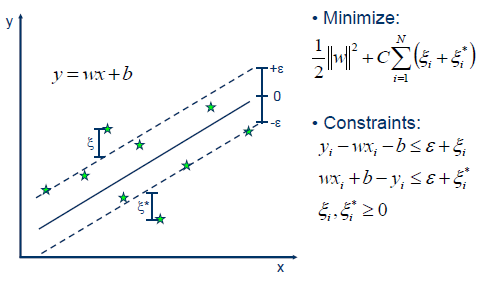

### Read the Dataset

In [1]:
import pandas as pd
import numpy as np

X_data = pd.read_csv('/kaggle/input/house-price-ready-to-modeling/X_HousePrice.csv')
X_data = X_data.set_index(['Unnamed: 0', 'Unnamed: 1'])
X_data.info()

X_train = X_data.loc['train']
X_test = X_data.loc['test']

y_data = pd.read_csv('/kaggle/input/house-price-ready-to-modeling/y_HousePrice.csv')
y_data = y_data.set_index(['Unnamed: 0', 'Id'])
y_data.info()

y_train = y_data.loc['train']
y_test = y_data.loc['test']

y_train_log = np.log(y_train.copy()).squeeze()
y_test_log = np.log(y_test.copy()).squeeze()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 1439 entries, ('train', 0) to ('test', 437)
Data columns (total 42 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   num__LotFrontage               1439 non-null   float64
 1   num__LotArea                   1439 non-null   float64
 2   num__OverallQual               1439 non-null   float64
 3   num__OverallCond               1439 non-null   float64
 4   num__BsmtUnfSF                 1439 non-null   float64
 5   num__TotalBsmtSF               1439 non-null   float64
 6   num__1stFlrSF                  1439 non-null   float64
 7   num__GrLivArea                 1439 non-null   float64
 8   num__BsmtFullBath              1439 non-null   float64
 9   num__HalfBath                  1439 non-null   float64
 10  num__TotRmsAbvGrd              1439 non-null   float64
 11  num__Fireplaces                1439 non-null   float64
 12  num__GarageCars             

In [1]:
!pip install --upgrade scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.4/13.4 MB 79.9 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spopt 0.6.0 requires shapely>=2.0.1, but you have shapely 1.8.5.post1 which is incompatible.


### Implement the Linear SVR model

### LinearSVR Hyperparameters

#### Regularization Parameter
- **`C`**: float, default=1.0
  - Regularization parameter. The strength of the regularization is inversely proportional to `C`. Must be strictly positive.

#### Loss Function
- **`loss`**: {‘epsilon_insensitive’, ‘squared_epsilon_insensitive’}, default=’epsilon_insensitive’
  - Specifies the loss function. The epsilon-insensitive loss (standard SVR) is the L1 loss, while the squared epsilon-insensitive loss (‘squared_epsilon_insensitive’) is the L2 loss.

#### Fit Intercept
- **`fit_intercept`**: bool, default=True
  - Whether or not to fit an intercept. If set to True, the feature vector is extended to include an intercept term: `[x_1, ..., x_n, 1]`, where `1` corresponds to the intercept. If set to False, no intercept will be used in calculations (i.e. data is expected to be already centered).

#### Random State
- **`random_state`**: int, RandomState instance or None, default=None
  - Controls the pseudo-random number generation for shuffling the data. Pass an int for reproducible output across multiple function calls. 

#### Maximum Iterations
- **`max_iter`**: int, default=1000
  - The maximum number of iterations to be run.


In [2]:
from sklearn.svm import LinearSVR
from sklearn.metrics import r2_score, root_mean_squared_error

lsvr = LinearSVR(C=1, loss='squared_epsilon_insensitive', fit_intercept=True, random_state=111, max_iter=10000000)
lsvr.fit(X_train, y_train_log)

y_pred_train = lsvr.predict(X_train)
y_pred_test = lsvr.predict(X_test)


# R-squared (R2) score for training set
r2_train = r2_score(y_train_log, y_pred_train)

# Root Mean Squared Error (RMSE) for training set
rmse_train = root_mean_squared_error(y_train_log, y_pred_train)

# Mean Absolute Percentage Error (MAPE) for training set
# Avoiding division by zero
y_train_values = y_train_log.to_numpy()
y_train_values = y_train_values.reshape(y_train_values.shape[0])
mape_train = np.mean(np.abs((y_train_values - y_pred_train) / np.where(y_train_values == 0, 1, y_train_values))) * 100

# Correlation between predicted and real values for training set
corr_train = np.corrcoef(y_train_values, y_pred_train.ravel())[0, 1]

print("R-squared (R2) score for Training Set:", r2_train)
print("Root Mean Squared Error (RMSE) for Training Set:", rmse_train)
print("Mean Absolute Percentage Error (MAPE) for Training Set:", mape_train)
print("Correlation between predicted and real values for Training Set:", corr_train)

print("#"*100)
#------------------------------------------------------------------------

# R-squared (R2) score
r2 = r2_score(y_test_log, y_pred_test)

# Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test_log, y_pred_test)

# Mean Absolute Percentage Error (MAPE)
# Avoiding division by zero
y_test_values = y_test_log.to_numpy()
y_test_values = y_test_values.reshape(y_test_values.shape[0])
mape = np.mean(np.abs((y_test_values - y_pred_test) / np.where(y_test_values == 0, 1, y_test_values))) * 100

# Correlation between predicted and real values
corr = np.corrcoef(y_test_values, y_pred_test.ravel())[0, 1]

print("R-squared (R2) score for Test Set:", r2)
print("Root Mean Squared Error (RMSE) for Test Set:", rmse)
print("Mean Absolute Percentage Error (MAPE) for Test Set:", mape)
print("Correlation between predicted and real values for Test Set:", corr)


R-squared (R2) score for Training Set: 0.9118298369927895
Root Mean Squared Error (RMSE) for Training Set: 0.11625489524238353
Mean Absolute Percentage Error (MAPE) for Training Set: 0.711850847198359
Correlation between predicted and real values for Training Set: 0.9550213273072164
####################################################################################################
R-squared (R2) score for Test Set: 0.8734026594136182
Root Mean Squared Error (RMSE) for Test Set: 0.13981019250151114
Mean Absolute Percentage Error (MAPE) for Test Set: 0.8999656646696377
Correlation between predicted and real values for Test Set: 0.9487083349379143


In [3]:
lsvr.coef_

array([ 0.00192729,  0.04339639,  0.09369159,  0.06431277, -0.0316098 ,
        0.07562046,  0.00086348,  0.13519055,  0.01564601,  0.01165182,
       -0.00983407,  0.00686374,  0.04474408, -0.00208385, -0.08333637,
       -0.00057728, -0.02672627,  0.00946167, -0.02277424, -0.00553527,
        0.00015223, -0.00088862, -0.00509301, -0.00523935,  0.00476514,
        0.00296343, -0.00057666, -0.00423398, -0.00222287, -0.01232656,
       -0.00081275,  0.0029917 , -0.00632544,  0.0114947 ,  0.01643546,
       -0.00466217, -0.00797825,  0.01466957,  0.01565072, -0.03119716,
        0.00745896,  0.0043493 ])

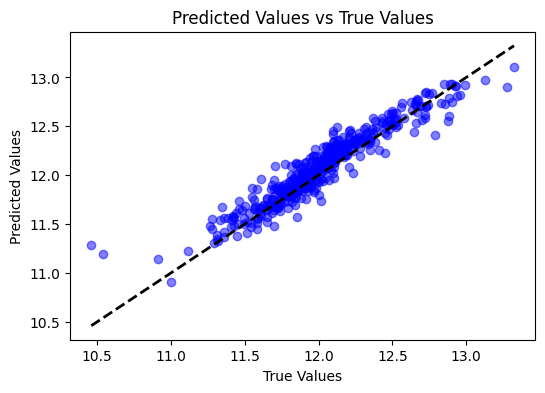

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.scatter(y_test_log, y_pred_test, color='blue', alpha=0.5)
plt.plot([y_test_log.min(), y_test_log.max()], [y_test_log.min(), y_test_log.max()], 'k--', lw=2)  # Plot the diagonal line
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.title('Predicted Values vs True Values')
plt.show()

### Identify the Optimal Model through Hyperparameter Tuning

In [5]:
from sklearn.svm import LinearSVR
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV

# Initialize the KNeighborsRegressor
lsvr = LinearSVR( fit_intercept=True, random_state=111, max_iter=10000000)

# Set up the parameter grid
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'loss': ['epsilon_insensitive', 'squared_epsilon_insensitive']
}


# Create GridSearchCV object
grid_search = GridSearchCV(lsvr, param_grid, scoring='neg_root_mean_squared_error', cv=5)

# Fit the grid search to the data
grid_search.fit(X_train, y_train_log)

# Get the best estimator
best_lsvr = grid_search.best_estimator_

# Get the best parameters
best_params = grid_search.best_params_
print("Best Parameters:", best_params)


Best Parameters: {'C': 100, 'loss': 'squared_epsilon_insensitive'}


In [6]:
# Train the regressor with the full training data
best_lsvr.fit(X_train, y_train_log)

# Predict the target for the train set
y_pred_train = best_lsvr.predict(X_train)

# Predict the target for the test set
y_pred = best_lsvr.predict(X_test)

# R-squared (R2) score for training set
r2_train = r2_score(y_train_log, y_pred_train)

# Root Mean Squared Error (RMSE) for training set
rmse_train = root_mean_squared_error(y_train_log, y_pred_train)

# Mean Absolute Percentage Error (MAPE) for training set
# Avoiding division by zero
y_train_values = y_train_log.to_numpy()
y_train_values = y_train_values.reshape(y_train_values.shape[0])
mape_train = np.mean(np.abs((y_train_values - y_pred_train) / np.where(y_train_values == 0, 1, y_train_values))) * 100

# Correlation between predicted and real values for training set
corr_train = np.corrcoef(y_train_values, y_pred_train.ravel())[0, 1]

print("R-squared (R2) score for Training Set:", r2_train)
print("Root Mean Squared Error (RMSE) for Training Set:", rmse_train)
print("Mean Absolute Percentage Error (MAPE) for Training Set:", mape_train)
print("Correlation between predicted and real values for Training Set:", corr_train)

print("#"*100)
#------------------------------------------------------------------------

# R-squared (R2) score
r2 = r2_score(y_test_log, y_pred)

# Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test_log, y_pred)

# Mean Absolute Percentage Error (MAPE)
# Avoiding division by zero
y_test_values = y_test_log.to_numpy()
y_test_values = y_test_values.reshape(y_test_values.shape[0])
mape = np.mean(np.abs((y_test_values - y_pred) / np.where(y_test_values == 0, 1, y_test_values))) * 100

# Correlation between predicted and real values
corr = np.corrcoef(y_test_values, y_pred.ravel())[0, 1]

print("R-squared (R2) score for Test Set:", r2)
print("Root Mean Squared Error (RMSE) for Test Set:", rmse)
print("Mean Absolute Percentage Error (MAPE) for Test Set:", mape)
print("Correlation between predicted and real values for Test Set:", corr)

R-squared (R2) score for Training Set: 0.9120655858156824
Root Mean Squared Error (RMSE) for Training Set: 0.1160993704115217
Mean Absolute Percentage Error (MAPE) for Training Set: 0.7064417897606079
Correlation between predicted and real values for Training Set: 0.9550212657415841
####################################################################################################
R-squared (R2) score for Test Set: 0.868724508722601
Root Mean Squared Error (RMSE) for Test Set: 0.1423699617958932
Mean Absolute Percentage Error (MAPE) for Test Set: 0.922495287195341
Correlation between predicted and real values for Test Set: 0.9486589429968638


### Non-Linear Kernel-Based SVR
Non-linear kernel-based SVM, such as those using **polynomial**, **radial basis function** (RBF), or **sigmoid** kernels, extends the capability of SVM to capture **complex, non-linear relationships** between features and the target variable. *These kernels transform the input space into a higher-dimensional space where a linear separation is possible*. This approach allows SVM to create flexible decision boundaries, making it powerful for tasks where the relationship between features and the target is not straightforward. While more **computationally intensive**, non-linear SVR models can achieve higher accuracy in capturing intricate patterns in the data.  

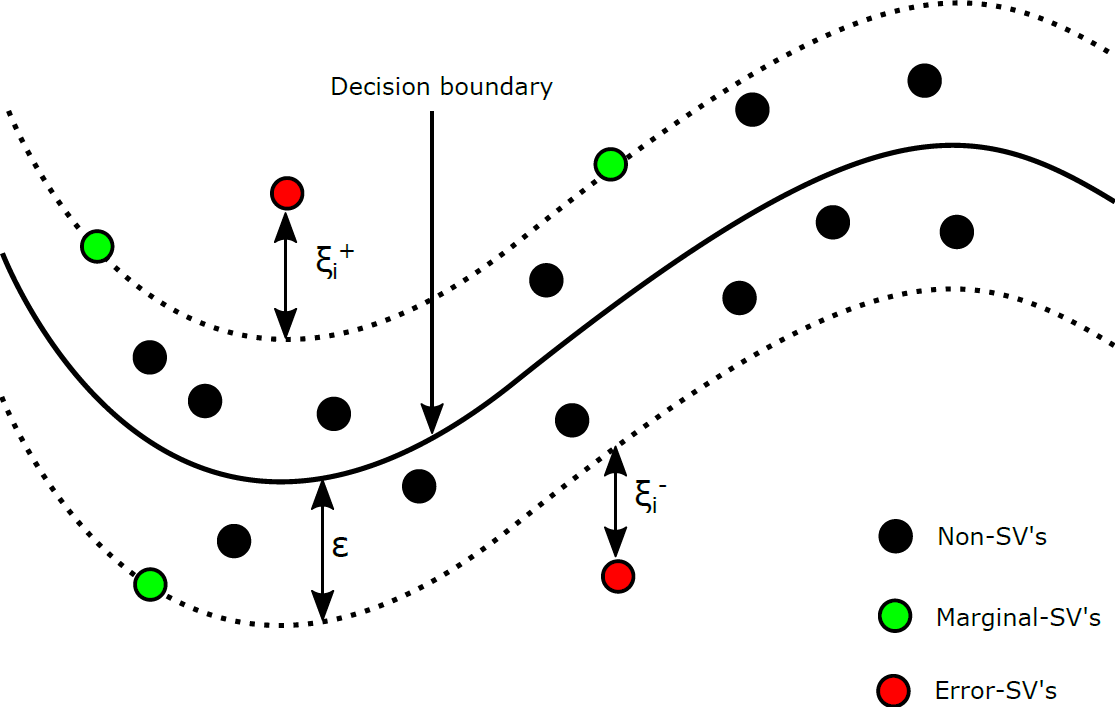

### Implement the Non-Linear SVR model

### SVR Hyperparameters

#### Kernel
- **`kernel`**: {‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’} or callable, default=’rbf’
  - Specifies the kernel type to be used in the algorithm. If none is given, ‘rbf’ will be used. If a callable is given, it is used to precompute the kernel matrix.

#### Degree
- **`degree`**: int, default=3
  - Degree of the polynomial kernel function (‘poly’). Must be non-negative. Ignored by all other kernels.

#### Gamma
- **`gamma`**: {‘scale’, ‘auto’} or float, default=’scale’
  - Kernel coefficient for ‘rbf’, ‘poly’, and ‘sigmoid’. If `gamma='scale'` (default) is passed, then it uses `1 / (n_features * X.var())` as the value of gamma. If `‘auto’`, it uses `1 / n_features`. If float, must be non-negative. 

#### coef0
- **`coef0`**: float, default=0.0
  - Independent term in kernel function. It is only significant in ‘poly’ and ‘sigmoid’.

#### Regularization Parameter
- **`C`**: float, default=1.0
  - Regularization parameter. The strength of the regularization is inversely proportional to `C`. Must be strictly positive. The penalty is a squared l2. For an intuitive visualization of the effects of scaling the regularization parameter `C`.

#### Shrinking
- **`shrinking`**: bool, default=True
  - Whether to use the shrinking heuristic. 

#### Max Iterations
- **`max_iter`**: int, default=-1
  - Hard limit on iterations within solver, or -1 for no limit.


In [7]:
from sklearn.svm import SVR
from sklearn.metrics import r2_score, root_mean_squared_error

svr = SVR(C=1.0, kernel='rbf', degree=3, gamma='scale', coef0=0.0, shrinking=True, max_iter=-1)
svr.fit(X_train, y_train_log)

y_pred_train = svr.predict(X_train)
y_pred_test = svr.predict(X_test)


# R-squared (R2) score for training set
r2_train = r2_score(y_train_log, y_pred_train)

# Root Mean Squared Error (RMSE) for training set
rmse_train = root_mean_squared_error(y_train_log, y_pred_train)

# Mean Absolute Percentage Error (MAPE) for training set
# Avoiding division by zero
y_train_values = y_train_log.to_numpy()
y_train_values = y_train_values.reshape(y_train_values.shape[0])
mape_train = np.mean(np.abs((y_train_values - y_pred_train) / np.where(y_train_values == 0, 1, y_train_values))) * 100

# Correlation between predicted and real values for training set
corr_train = np.corrcoef(y_train_values, y_pred_train.ravel())[0, 1]

print("R-squared (R2) score for Training Set:", r2_train)
print("Root Mean Squared Error (RMSE) for Training Set:", rmse_train)
print("Mean Absolute Percentage Error (MAPE) for Training Set:", mape_train)
print("Correlation between predicted and real values for Training Set:", corr_train)

print("#"*100)
#------------------------------------------------------------------------

# R-squared (R2) score
r2 = r2_score(y_test_log, y_pred_test)

# Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test_log, y_pred_test)

# Mean Absolute Percentage Error (MAPE)
# Avoiding division by zero
y_test_values = y_test_log.to_numpy()
y_test_values = y_test_values.reshape(y_test_values.shape[0])
mape = np.mean(np.abs((y_test_values - y_pred_test) / np.where(y_test_values == 0, 1, y_test_values))) * 100

# Correlation between predicted and real values
corr = np.corrcoef(y_test_values, y_pred_test.ravel())[0, 1]

print("R-squared (R2) score for Test Set:", r2)
print("Root Mean Squared Error (RMSE) for Test Set:", rmse)
print("Mean Absolute Percentage Error (MAPE) for Test Set:", mape)
print("Correlation between predicted and real values for Test Set:", corr)

R-squared (R2) score for Training Set: 0.9589568626700499
Root Mean Squared Error (RMSE) for Training Set: 0.07931780781602968
Mean Absolute Percentage Error (MAPE) for Training Set: 0.5588621874620392
Correlation between predicted and real values for Training Set: 0.9795576075531117
####################################################################################################
R-squared (R2) score for Test Set: 0.5850857720521374
Root Mean Squared Error (RMSE) for Test Set: 0.25310790327432076
Mean Absolute Percentage Error (MAPE) for Test Set: 1.4822125935498458
Correlation between predicted and real values for Test Set: 0.8774062762900077


### Identify the Optimal Model through Hyperparameter Tuning

In [8]:
from sklearn.svm import SVR
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV

# Initialize the KNeighborsRegressor
svr = SVR( max_iter=-1, verbose=False)

# Set up the parameter grid with specific parameters for each kernel
param_grid = [
    {'kernel': ['linear'], 'C': [0.001, 0.01, 0.1, 1, 10, 100]},
    {'kernel': ['poly'], 'C': [0.001, 0.01, 0.1, 1, 10, 100], 'degree': [2, 3, 4],
            'gamma': ['scale', 'auto'], 'coef0': [0.0, 0.1, 0.5, 1]},
    {'kernel': ['rbf'], 'C': [0.001, 0.01, 0.1, 1, 10, 100], 'gamma': ['scale', 'auto']},
    {'kernel': ['sigmoid'], 'C': [0.001, 0.01, 0.1, 1, 10, 100], 'gamma': ['scale', 'auto'], 'coef0': [0.0, 0.1, 0.5, 1]}
]


# Create GridSearchCV object
grid_search = GridSearchCV(svr, param_grid, scoring='neg_root_mean_squared_error', cv=5)

# Fit the grid search to the data
grid_search.fit(X_train, y_train_log)

# Get the best estimator
best_svr = grid_search.best_estimator_

# Get the best parameters
best_params = grid_search.best_params_
print("Best Parameters:", best_params)

Best Parameters: {'C': 0.1, 'coef0': 1, 'degree': 2, 'gamma': 'auto', 'kernel': 'poly'}


In [9]:
# Train the regressor with the full training data
best_svr.fit(X_train, y_train_log)

# Predict the target for the train set
y_pred_train = best_svr.predict(X_train)

# Predict the target for the test set
y_pred = best_svr.predict(X_test)

# R-squared (R2) score for training set
r2_train = r2_score(y_train_log, y_pred_train)

# Root Mean Squared Error (RMSE) for training set
rmse_train = root_mean_squared_error(y_train_log, y_pred_train)

# Mean Absolute Percentage Error (MAPE) for training set
# Avoiding division by zero
y_train_values = y_train_log.to_numpy()
y_train_values = y_train_values.reshape(y_train_values.shape[0])
mape_train = np.mean(np.abs((y_train_values - y_pred_train) / np.where(y_train_values == 0, 1, y_train_values))) * 100

# Correlation between predicted and real values for training set
corr_train = np.corrcoef(y_train_values, y_pred_train.ravel())[0, 1]

print("R-squared (R2) score for Training Set:", r2_train)
print("Root Mean Squared Error (RMSE) for Training Set:", rmse_train)
print("Mean Absolute Percentage Error (MAPE) for Training Set:", mape_train)
print("Correlation between predicted and real values for Training Set:", corr_train)

print("#"*100)
#------------------------------------------------------------------------

# R-squared (R2) score
r2 = r2_score(y_test_log, y_pred)

# Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test_log, y_pred)

# Mean Absolute Percentage Error (MAPE)
# Avoiding division by zero
y_test_values = y_test_log.to_numpy()
y_test_values = y_test_values.reshape(y_test_values.shape[0])
mape = np.mean(np.abs((y_test_values - y_pred) / np.where(y_test_values == 0, 1, y_test_values))) * 100

# Correlation between predicted and real values
corr = np.corrcoef(y_test_values, y_pred.ravel())[0, 1]

print("R-squared (R2) score for Test Set:", r2)
print("Root Mean Squared Error (RMSE) for Test Set:", rmse)
print("Mean Absolute Percentage Error (MAPE) for Test Set:", mape)
print("Correlation between predicted and real values for Test Set:", corr)

R-squared (R2) score for Training Set: 0.9368978387748893
Root Mean Squared Error (RMSE) for Training Set: 0.09834958784501799
Mean Absolute Percentage Error (MAPE) for Training Set: 0.61839032405138
Correlation between predicted and real values for Training Set: 0.9680377324152151
####################################################################################################
R-squared (R2) score for Test Set: 0.7345234666378357
Root Mean Squared Error (RMSE) for Test Set: 0.20246017660035937
Mean Absolute Percentage Error (MAPE) for Test Set: 1.4064415114627744
Correlation between predicted and real values for Test Set: 0.9468761567777169
